# VoiceScope — Audio Deepfake Dataset Visualization
Khám phá **ASVspoof 2019 Logical Access** trước khi huấn luyện: cấu trúc, nhãn,
phân bố, tín hiệu và giới hạn dữ liệu. Đây là benchmark tiếng Anh; không đại diện
cho chất lượng phát hiện deepfake tiếng Việt. Không huấn luyện DINOv3 trong notebook này.

Bố cục tham khảo: [Sentinel-2 RPG Dataset Visualization](https://www.kaggle.com/code/loanhviet/sentinel-2-rpg-dataset-visualization/notebook).
Nội dung và biểu đồ dưới đây được xây dựng riêng cho audio.

**Cách chạy:** Add Input bộ ASVspoof 2019 đã giải nén, giữ protocol LA và audio FLAC.
CPU, Internet off. Không cần weights, token, source GitHub hoặc dữ liệu riêng.

Outputs local: ASVspoof 2019 LA; audio sample seed 42, 600 clips.


## 1. Setup và phạm vi khảo sát

In [1]:
from pathlib import Path
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import soundfile as sf
from scipy.signal import spectrogram
from IPython.display import display
SEED = 42
ROOT = Path(os.environ.get('VOICESCOPE_EDA_INPUT', '/kaggle/input'))
SAMPLE_PER_GROUP = 100  # khảo sát audio tối đa 100 clip mỗi split/nhãn
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .18})
COLORS = ['#168b88', '#e58b45']
print('Metadata: toàn bộ protocol LA. Audio: mẫu phân tầng, seed =', SEED)


Metadata: toàn bộ protocol LA. Audio: mẫu phân tầng, seed = 42


## 2. Cấu trúc và kiểm tra protocol
Giữ nguyên train/dev/eval chính thức. Không suy nhãn từ tên file hoặc biên độ.

In [2]:
protocols = []
for folder, dirs, files in os.walk(ROOT):
    dirs[:] = [d for d in dirs if d.lower() not in ('flac', 'wav', 'audio')]
    protocols.extend(Path(folder) / name for name in files
                     if name.startswith('ASVspoof2019.LA.cm.') and name.endswith('.txt'))
protocols.sort()
frames = []
for path in protocols:
    split = next((s for s in ('train', 'dev', 'eval') if f'.{s}.' in path.name), None)
    if split is None:
        continue
    table = pd.read_csv(path, sep=r'\s+', header=None,
                        names=['speaker', 'clip', 'system', 'attack', 'label'], dtype=str)
    table['split'] = split
    frames.append(table)
if not frames:
    raise FileNotFoundError('Add Input: ASVspoof 2019 LA đã giải nén, gồm CM protocols và FLAC.')
df = pd.concat(frames, ignore_index=True)
if df.duplicated(['split', 'clip']).any():
    raise ValueError('Protocol trùng: chỉ gắn một bản dataset hoặc đặt ROOT cụ thể hơn.')
if not df.label.isin(['bonafide', 'spoof']).all():
    raise ValueError('Protocol có nhãn không hợp lệ.')
df['label'] = df.label.map({'bonafide':'real', 'spoof':'fake'})
display(pd.DataFrame({'clips':[len(df)], 'speakers':[df.speaker.nunique()],
                      'splits':[df.split.nunique()]}))
display(df.groupby(['split','label']).size().unstack(fill_value=0))


    clips  speakers  splits
0  121461       107       3
label   fake  real
split             
dev    22296  2548
eval   63882  7355
train  22800  2580


## 3. Phân bố nhãn và các kiểu tấn công
Số lượng dưới đây tính trên toàn bộ protocol, không phải mẫu audio.

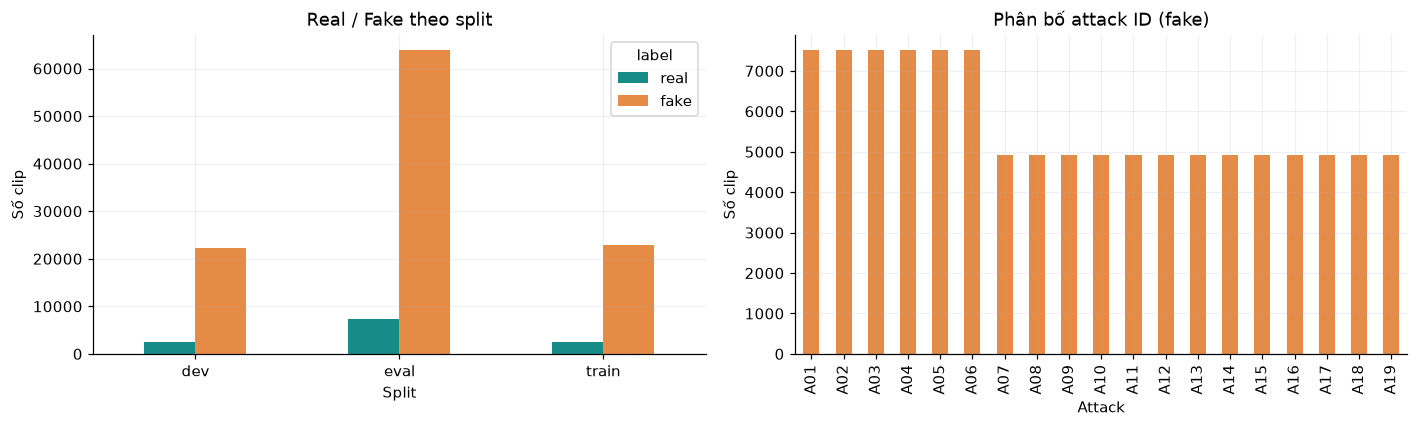

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
df.groupby(['split','label']).size().unstack(fill_value=0).reindex(columns=['real','fake']).plot.bar(ax=axes[0], color=COLORS, rot=0)
axes[0].set(title='Real / Fake theo split', ylabel='Số clip', xlabel='Split')
df[df.label.eq('fake')].attack.value_counts().sort_index().plot.bar(ax=axes[1], color=COLORS[1])
axes[1].set(title='Phân bố attack ID (fake)', ylabel='Số clip', xlabel='Attack')
plt.tight_layout(); plt.show()


## 4. Thời lượng, sample rate và chất lượng đọc audio
Lấy mẫu phân tầng theo split/nhãn. Thống kê thời lượng chỉ mô tả mẫu đọc thành công; báo riêng tệp thiếu/lỗi.

Số clip lấy mẫu: 600 | Đọc được: 600 | Lỗi: 0
             count   min  median  mean   max
split label                                 
dev   fake     100  1.17    3.26  3.57  9.69
      real     100  1.62    3.39  3.52  5.80
eval  fake     100  0.89    2.85  3.28  8.70
      real     100  1.49    3.17  3.35  8.36
train fake     100  1.51    3.15  3.43  8.92
      real     100  1.74    3.41  3.52  7.38


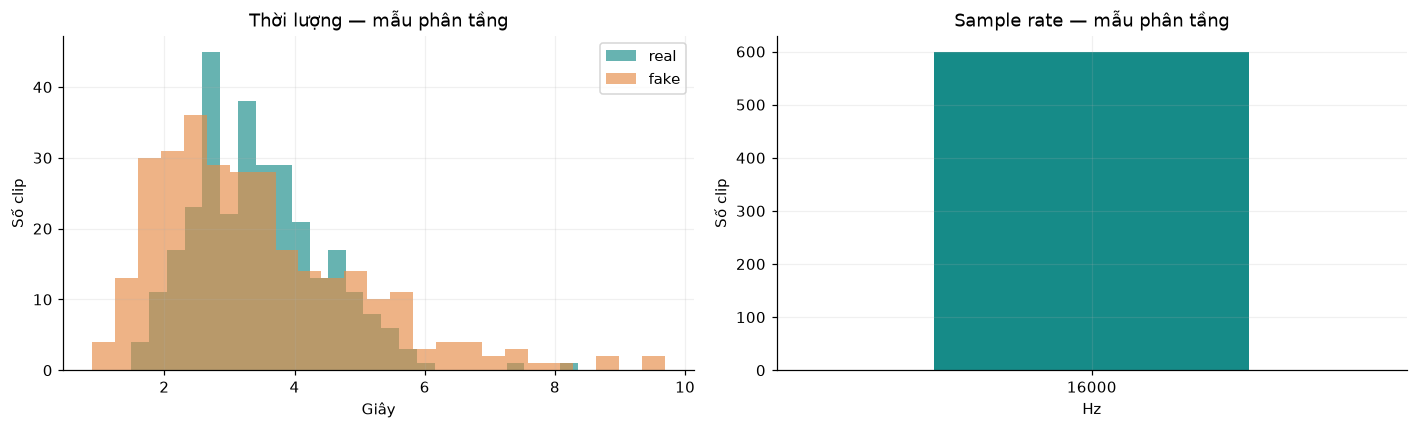

In [4]:
sample = df.groupby(['split','label'], group_keys=False).sample(n=1, random_state=SEED)
sample = pd.concat([g.sample(min(len(g), SAMPLE_PER_GROUP), random_state=SEED)
                    for _, g in df.groupby(['split','label'])])
paths = {}
for p in ROOT.rglob('*.flac'):
    if p.stem in paths:
        raise ValueError('Audio ID trùng; chọn ROOT chỉ chứa một bản LA dataset.')
    paths[p.stem] = p
records, failures = [], []
for row in sample.itertuples():
    p = paths.get(row.clip)
    try:
        if p is None: raise FileNotFoundError('missing')
        info = sf.info(p)
        records.append(dict(clip=row.clip, split=row.split, label=row.label,
                            seconds=info.duration, sample_rate=info.samplerate,
                            channels=info.channels))
    except Exception as exc:
        failures.append({'split':row.split, 'label':row.label, 'reason':type(exc).__name__})
audio = pd.DataFrame(records)
print('Số clip lấy mẫu:', len(sample), '| Đọc được:', len(audio), '| Lỗi:', len(failures))
if failures: display(pd.DataFrame(failures).value_counts().rename('count').reset_index())
if audio.empty: raise RuntimeError('Không có FLAC đọc được; kiểm tra Add Input.')
display(audio.groupby(['split','label']).seconds.agg(['count','min','median','mean','max']).round(2))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for label, color in zip(['real','fake'], COLORS):
    axes[0].hist(audio.loc[audio.label.eq(label),'seconds'], bins=25, alpha=.65, label=label, color=color)
axes[0].set(title='Thời lượng — mẫu phân tầng', xlabel='Giây', ylabel='Số clip'); axes[0].legend()
audio.sample_rate.value_counts().sort_index().plot.bar(ax=axes[1], color=COLORS[0], rot=0)
axes[1].set(title='Sample rate — mẫu phân tầng', xlabel='Hz', ylabel='Số clip')
plt.tight_layout(); plt.show()


## 5. Waveform và phổ thời gian–tần số
Một clip mỗi nhãn, tối đa 8 giây đầu. Phổ STFT dB tham chiếu đỉnh từng clip; không phải bản đồ mức độ giả. Không nhúng hoặc xuất audio vào notebook public.

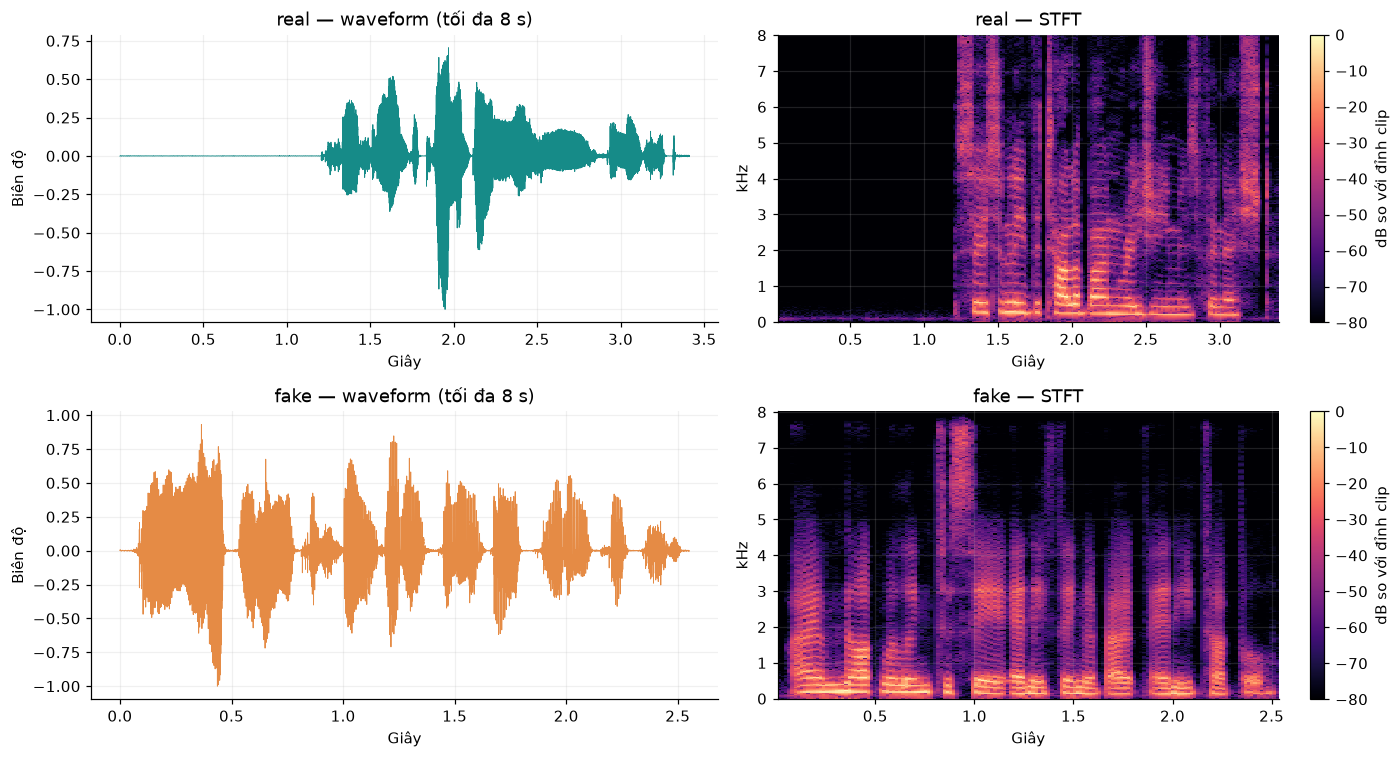

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(13, 7), squeeze=False)
for i, label in enumerate(['real','fake']):
    candidates = audio[audio.label.eq(label)]
    if candidates.empty:
        axes[i,0].text(.1,.5,'Không có audio nhãn ' + label); continue
    selected = candidates.sort_values('clip').iloc[0]
    y, sr = sf.read(paths[selected['clip']], frames=int(selected.sample_rate * 8), dtype='float32', always_2d=True)
    y = y.mean(axis=1)
    axes[i,0].plot(np.arange(len(y))/sr, y, color=COLORS[i], linewidth=.6)
    axes[i,0].set(title=f'{label} — waveform (tối đa 8 s)', xlabel='Giây', ylabel='Biên độ')
    n = min(512, len(y))
    f, t, power = spectrogram(y, sr, nperseg=n, noverlap=n//2)
    db = 10*np.log10(np.maximum(power, 1e-12)/max(float(power.max()), 1e-12))
    im = axes[i,1].pcolormesh(t, f/1000, db, shading='auto', cmap='magma', vmin=-80, vmax=0)
    axes[i,1].set(title=f'{label} — STFT', xlabel='Giây', ylabel='kHz')
    fig.colorbar(im, ax=axes[i,1], label='dB so với đỉnh clip')
plt.tight_layout(); plt.show()


## 6. Kiểm tra phân tách người nói
Đếm giao speaker ID giữa các split. Kết quả này không thay thế kiểm tra trùng waveform, nguồn thu hoặc lineage của dữ liệu bổ sung.

In [6]:
splits = sorted(df.split.unique())
overlap = pd.DataFrame(index=splits, columns=splits, dtype=int)
for a in splits:
    for b in splits:
        overlap.loc[a,b] = len(set(df.loc[df.split.eq(a),'speaker']) & set(df.loc[df.split.eq(b),'speaker']))
display(overlap.astype(int))
print('Đường chéo: số speaker trong split. Ngoài đường chéo: số speaker chung.')


       dev  eval  train
dev     20     0      0
eval     0    67      0
train    0     0     20
Đường chéo: số speaker trong split. Ngoài đường chéo: số speaker chung.


## 7. Tổng kết và bước tiếp theo
- Đối chiếu mất cân bằng lớp và attack ID trước khi chọn cách lấy mẫu train.
- Phân bố thời lượng/sample rate chỉ đại diện mẫu khảo sát có ghi seed và cỡ mẫu.
- Waveform và STFT giúp kiểm tra tín hiệu; không chứng minh tính thật/giả bằng mắt.
- ASVspoof LA là benchmark; cần corpus tiếng Việt có quyền sử dụng để đánh giá mục tiêu VoiceScope.
- Chưa có accuracy, F1, EER hoặc detector đã huấn luyện trong bài này.
- Notebook chỉ trình bày thống kê và biểu đồ; không đóng gói audio/metadata định danh để công bố lại.

Nguồn: [ASVspoof 2019](https://www.asvspoof.org/index2019.html).
